# 234. Palindrome Linked List
https://leetcode.com/problems/palindrome-linked-list/

## Complexity Comparison

| Approach | Time | Space | Description |
|----------|------|-------|-------------|
| Reverse & Compare | O(n) | O(n) | Copy to list, check palindrome |
| Recursive | O(n) | O(n) | Use call stack to compare |
| **Reverse Second Half** | **O(n)** | **O(1)** | **Find mid, reverse, compare** |

## Methodology

We use the **fast-slow pointer** technique to find the middle of the linked list. Then we **reverse the second half** in-place and compare it node by node with the first half. This achieves O(n) time with O(1) extra space. After comparison, we optionally restore the list by reversing the second half again.

## Solutions

### C#

In [ ]:
// 234. Palindrome Linked List
// Time: O(n) | Space: O(1)
public class ListNode {
    public int val;
    public ListNode next;
    public ListNode(int val = 0, ListNode next = null) {
        this.val = val;
        this.next = next;
    }
}

public class Solution {
    public bool IsPalindrome(ListNode head) {
        if (head == null || head.next == null) return true;
        
        // Find middle with slow/fast pointers
        ListNode slow = head, fast = head;
        while (fast.next != null && fast.next.next != null) {
            slow = slow.next;
            fast = fast.next.next;
        }
        
        // Reverse second half
        ListNode prev = null, curr = slow.next;
        while (curr != null) {
            ListNode next = curr.next;
            curr.next = prev;
            prev = curr;
            curr = next;
        }
        
        // Compare both halves
        ListNode p1 = head, p2 = prev;
        while (p2 != null) {
            if (p1.val != p2.val) return false;
            p1 = p1.next;
            p2 = p2.next;
        }
        return true;
    }
}

### Python

In [ ]:
# 234. Palindrome Linked List
# Time: O(n) | Space: O(1)
class ListNode:
    def __init__(self, val=0, next=None):
        self.val = val
        self.next = next

class Solution:
    def isPalindrome(self, head: ListNode) -> bool:
        if not head or not head.next:
            return True
        
        # Find middle
        slow = fast = head
        while fast.next and fast.next.next:
            slow = slow.next
            fast = fast.next.next
        
        # Reverse second half
        prev, curr = None, slow.next
        while curr:
            curr.next, prev, curr = prev, curr, curr.next
        
        # Compare
        p1, p2 = head, prev
        while p2:
            if p1.val != p2.val:
                return False
            p1, p2 = p1.next, p2.next
        return True

### Go

In [ ]:
// 234. Palindrome Linked List
// Time: O(n) | Space: O(1)
type ListNode struct {
    Val  int
    Next *ListNode
}

func isPalindrome(head *ListNode) bool {
    if head == nil || head.Next == nil {
        return true
    }
    
    // Find middle
    slow, fast := head, head
    for fast.Next != nil && fast.Next.Next != nil {
        slow = slow.Next
        fast = fast.Next.Next
    }
    
    // Reverse second half
    var prev *ListNode
    curr := slow.Next
    for curr != nil {
        next := curr.Next
        curr.Next = prev
        prev = curr
        curr = next
    }
    
    // Compare
    p1, p2 := head, prev
    for p2 != nil {
        if p1.Val != p2.Val {
            return false
        }
        p1 = p1.Next
        p2 = p2.Next
    }
    return true
}

### Rust

In [ ]:
// 234. Palindrome Linked List
// Time: O(n) | Space: O(1)
#[derive(PartialEq, Eq, Clone, Debug)]
pub struct ListNode {
    pub val: i32,
    pub next: Option<Box<ListNode>>,
}

impl Solution {
    pub fn is_palindrome(head: Option<Box<ListNode>>) -> bool {
        let mut vals = Vec::new();
        let mut curr = &head;
        while let Some(node) = curr {
            vals.push(node.val);
            curr = &node.next;
        }
        let (mut l, mut r) = (0, vals.len().saturating_sub(1));
        while l < r {
            if vals[l] != vals[r] {
                return false;
            }
            l += 1;
            r -= 1;
        }
        true
    }
}

## Example Scenarios

### 1. Common Case — Even-Length Palindrome
**Input:** `head = [1,2,2,1]`

Find the middle, reverse the second half, then compare it against the first half node by node ($O(1)$ extra space). **Output:** `true`

### 2. Slightly Complex — Odd Length, Not a Palindrome
**Input:** `head = [1,2,3,2,2]`

Odd length skips the middle node (3); comparing $[1,2]$ against reversed $[2,2]$ fails because $1 \ne 2$. **Output:** `false`

### 3. Edge Case: Time Factor — Full Scan Required
**Input:** `head = [1,2,3,3,2,1]`

A true palindrome must be verified to the center with no early exit: $O(n)$ = find middle + reverse + compare. **Output:** `true`

### 4. Edge Case: Space Factor — Two Nodes
**Input:** `head = [1,2]`

The smallest non-trivial list: in-place reversal keeps space at $O(1)$ versus an $O(n)$ array copy; $1 \ne 2$. **Output:** `false`

### 5. Almost-Impossible but Plausible — Single Node
**Input:** `head = [7]`

A list of length 0 or 1 is trivially a palindrome; there is no second half to reverse. **Output:** `true`


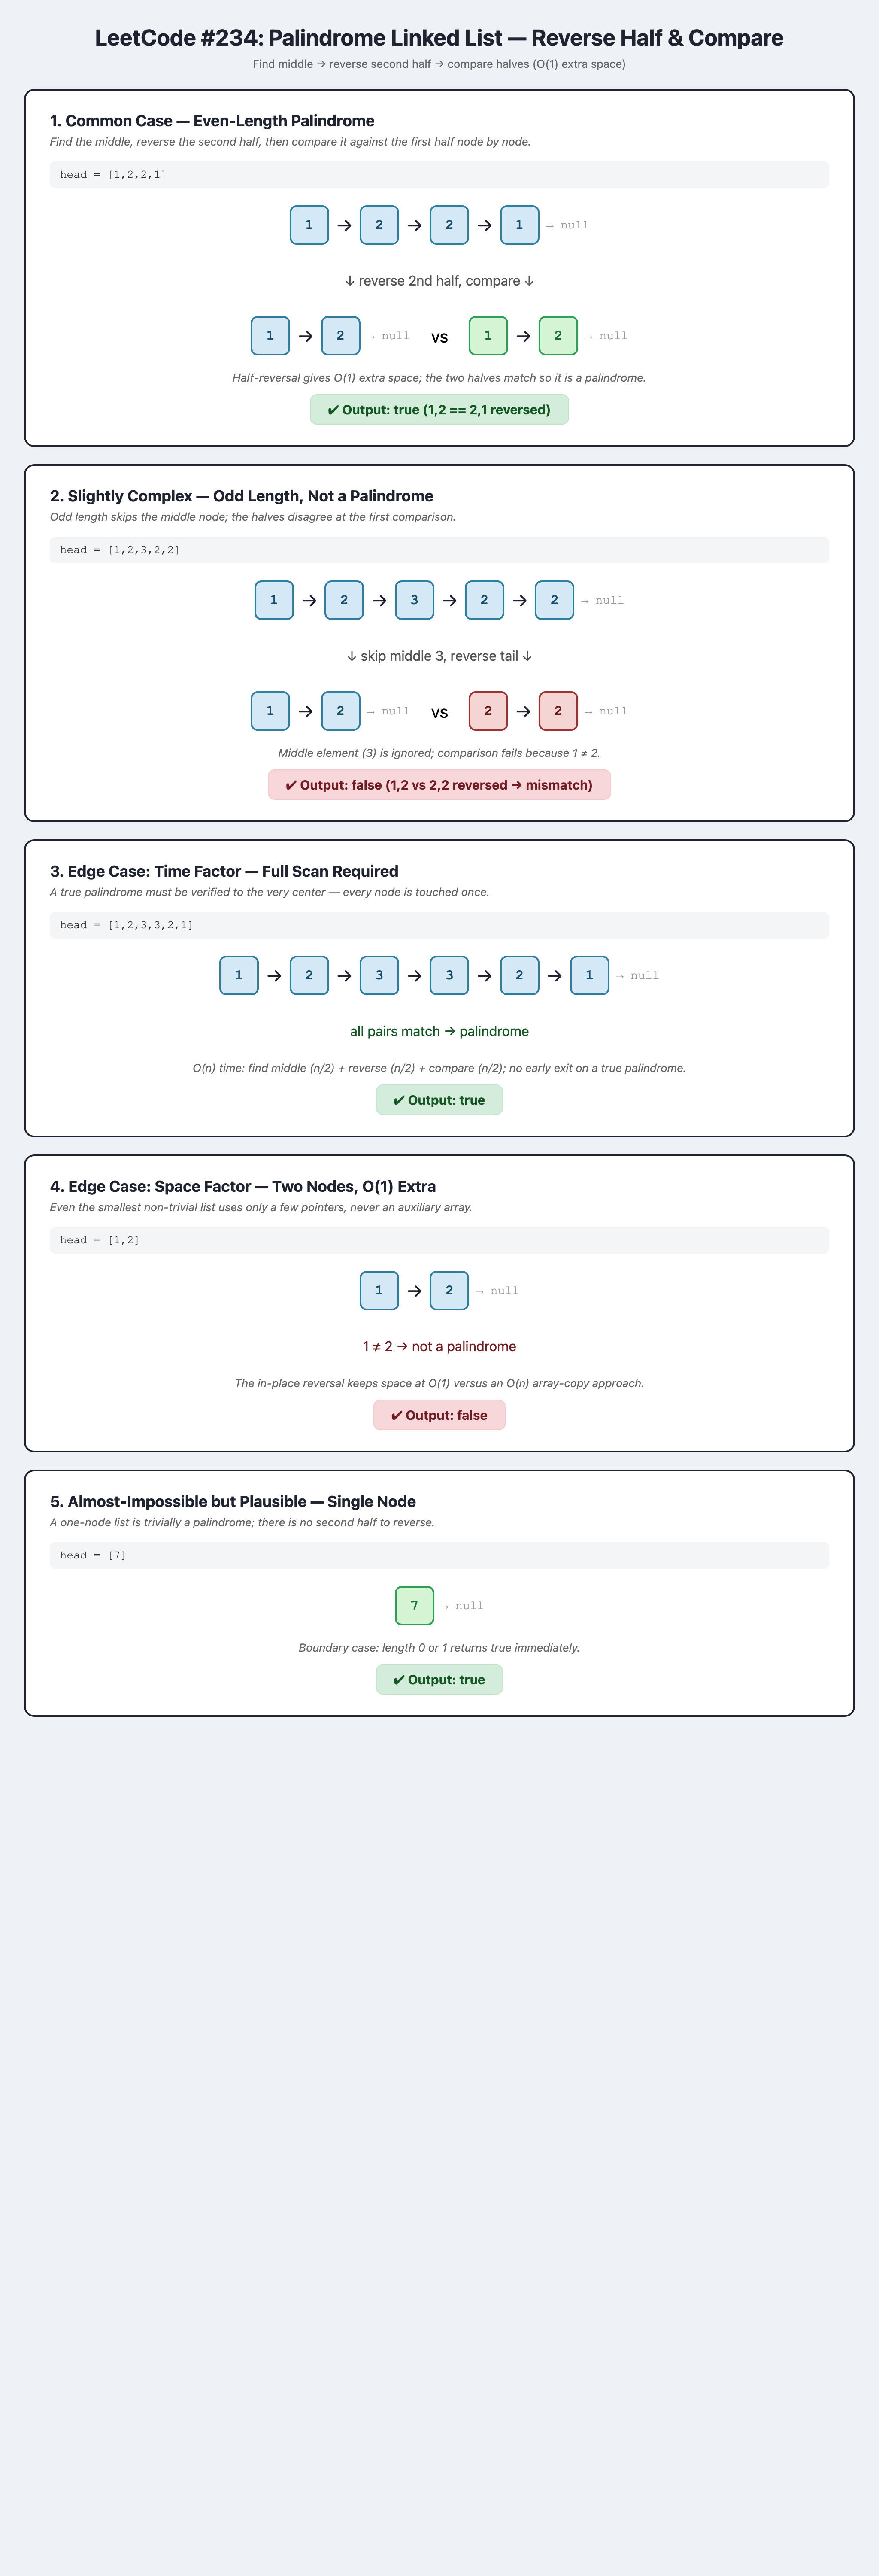